In [1]:
from sklearn import datasets

digits = datasets.load_digits()
data, target = digits.data, digits.target
data.shape, target.shape

((1797, 64), (1797,))

In [2]:
import matplotlib.pyplot as plt

_, axes = plt.subplots(nrows=1, ncols=8, figsize=(12, 2))
for ax, image, label in zip(axes, digits.images, digits.target):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation="nearest")
    ax.set_title(f"Label: {label}")
plt.show()

<Figure size 1200x200 with 8 Axes>

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    data, target, test_size=0.3, random_state=42, stratify=target,
)
X_train.shape, X_test.shape

((1257, 64), (540, 64))

In [4]:
from sklearn.svm import SVC

estimator = SVC(gamma=0.001, C=10)
estimator.fit(X_train, y_train)

SVC(C=10, gamma=0.001)

In [5]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_test = estimator.predict(X_test)
print(classification_report(y_test, y_pred_test))
accuracy_score(y_true=y_test, y_pred=y_pred_test)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        54
           1       0.95      1.00      0.97        55
           2       1.00      1.00      1.00        53
           3       1.00      1.00      1.00        55
           4       1.00      1.00      1.00        54
           5       1.00      0.98      0.99        55
           6       1.00      0.98      0.99        54
           7       0.98      1.00      0.99        54
           8       0.98      0.94      0.96        52
           9       0.98      0.98      0.98        54

    accuracy                           0.99       540
   macro avg       0.99      0.99      0.99       540
weighted avg       0.99      0.99      0.99       540



0.9888888888888889

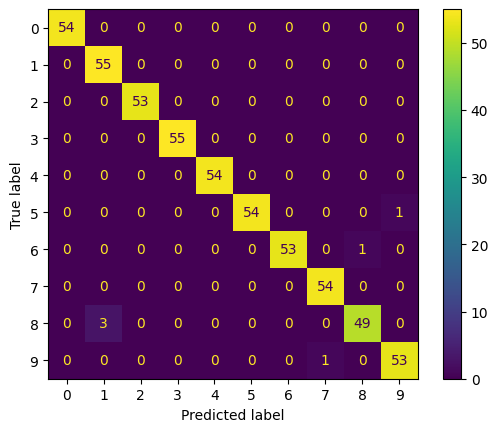

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test)
plt.show()

In [7]:
# Full-dataset accuracy, as evaluated by the test suite
accuracy_score(y_true=target, y_pred=estimator.predict(data))

0.996661101836394

In [8]:
import os
import pickle

os.makedirs("../submission", exist_ok=True)

with open("../submission/estimator.pkl", "wb") as file:
    pickle.dump(estimator, file)